# Imports and data

In [1]:
import time
from itertools import product
from joblib import dump

import matplotlib.pyplot as plt
import pandas as pd

from demand.data import clean, load_subset
from demand.features import build_features, usable_rows, FEATURES
from demand.metrics import evaluate
from demand.models import design, make_ridge, make_xgb, make_lgbm, ScaledTarget
from demand.validation import split_holdout, walk_forward_splits
from demand.config import MODELS

features = build_features(clean(load_subset()))
history_start = features.date.min()
train_part, holdout = split_holdout(features)

# Walk-forward for models

## Function helper

In [2]:
def run_walk_forward(make_model, features=FEATURES):
    rows, importances = [], []
    for fold, (train_dates, val_dates) in enumerate(walk_forward_splits(train_part.date), 1):
        train = usable_rows(train_part[train_part.date.isin(train_dates)], history_start)
        val = usable_rows(train_part[train_part.date.isin(val_dates)], history_start)

        model = make_model()
        start = time.perf_counter()
        model.fit(design(train, features), train.sales)
        fit_seconds = time.perf_counter() - start

        if hasattr(model, "feature_importances_"):
            importances.append(model.feature_importances_)

        pred = model.predict(design(val, features)).clip(min=0)
        rows.append({"fold": fold, **evaluate(val.sales, pred), "fit_s": fit_seconds})

    results = pd.DataFrame(rows).set_index("fold")
    importance = pd.DataFrame(importances, columns=features) if importances else None
    return results, importance

## Ridge

In [3]:
ridge, _ = run_walk_forward(make_ridge, FEATURES)
display(ridge.round(3))
display(ridge.mean().round(3))

,MAE,RMSE,WAPE,fit_s
fold,,,,
1,1111.320,1685.388,0.199,0.112
2,843.633,1394.639,0.172,0.059
3,833.372,1223.136,0.176,0.049
4,524.504,936.669,0.107,0.048
5,825.480,1179.771,0.176,0.061
6,778.911,1116.092,0.162,0.054
7,606.963,922.456,0.126,0.061
8,448.542,665.722,0.095,0.060


MAE       746.590
RMSE     1140.484
WAPE        0.152
fit_s       0.063
dtype: float64

## XGBoost

Runs on the current `FEATURES`. The first run with all features (WAPE 0.126) is recorded in the ablation sections below.

,MAE,RMSE,WAPE,fit_s
fold,,,,
1,892.486,1556.980,0.160,1.048
2,571.390,1074.089,0.116,0.942
3,592.761,989.085,0.125,0.902
4,452.168,838.447,0.093,0.969
5,575.346,995.565,0.123,1.120
6,515.976,852.937,0.107,0.915
7,487.071,804.789,0.101,0.957
8,339.810,548.639,0.072,0.975


MAE      553.376
RMSE     957.566
WAPE       0.112
fit_s      0.978
dtype: float64

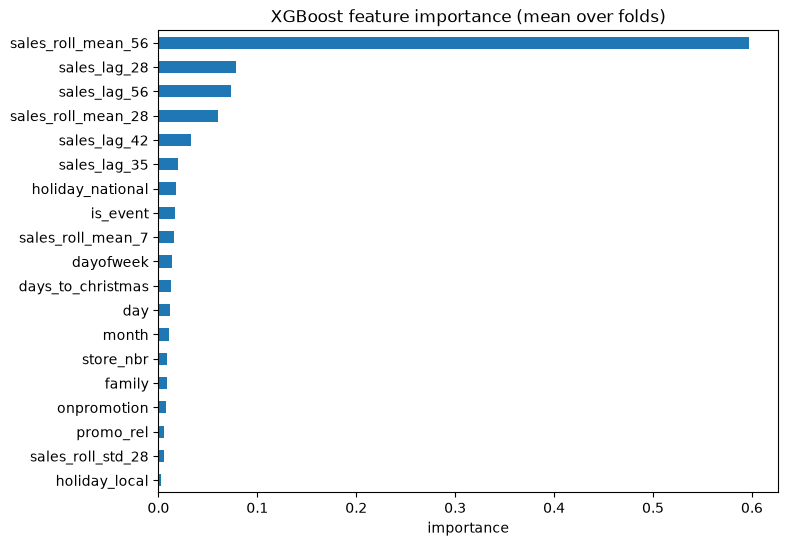

In [4]:
xgb, xgb_importance = run_walk_forward(make_xgb, FEATURES)
display(xgb.round(3))
display(xgb.mean().round(3))

xgb_importance.mean().sort_values().plot.barh(figsize=(8, 6), title="XGBoost feature importance (mean over folds)")
plt.xlabel("importance")
plt.show()

## XGBoost ablation: payday and oil

Recorded run: it used the feature set before `is_payday` and `oil_lag_28` were removed, so the code is kept as text and the cell is not re-run.

```python
drop = ["is_payday", "oil_lag_28"]
reduced = [f for f in FEATURES if f not in drop]
xgb_reduced, _ = run_walk_forward(make_xgb, reduced)

pd.DataFrame({"full": xgb.mean(), "without payday and oil": xgb_reduced.mean()}).round(3)
```

Result:

```
           full  without payday and oil
MAE     622.562                 553.376
RMSE   1012.835                 957.566
WAPE      0.126                   0.112
fit_s     1.188                   1.049
```

## XGBoost ablation by feature group

Recorded run: it used the feature set before `is_payday` and `oil_lag_28` were removed, so the code is kept as text and the cell is not re-run.

```python
groups = {
    "oil": ["oil_lag_28"],
    "payday": ["is_payday"],
    "raw onpromotion": ["onpromotion"],
    "oil + payday + raw onpromotion": ["oil_lag_28", "is_payday", "onpromotion"],
}

ablation = {"all features": xgb.mean()}
for name, cols in groups.items():
    kept = [f for f in FEATURES if f not in cols]
    result, _ = run_walk_forward(make_xgb, kept)
    ablation[f"without {name}"] = result.mean()

pd.DataFrame(ablation).T.round(3)
```

Result:

```
                                            MAE      RMSE   WAPE  fit_s
all features                            622.562  1012.835  0.126  1.188
without oil                             554.140   951.852  0.112  1.017
without payday                          622.306  1015.032  0.126  1.014
without raw onpromotion                 607.486   992.224  0.123  0.903
without oil + payday + raw onpromotion  551.405   956.027  0.112  0.885
```

## LightGBM

In [5]:
lgbm, lgbm_importance = run_walk_forward(make_lgbm, FEATURES)
display(lgbm.round(3))
display(lgbm.mean().round(3))

,MAE,RMSE,WAPE,fit_s
fold,,,,
1,887.276,1443.567,0.159,0.990
2,571.551,1044.552,0.116,0.724
3,609.654,1017.277,0.129,0.944
4,445.997,817.612,0.091,0.858
5,577.611,996.376,0.123,0.755
6,507.391,831.349,0.106,0.830
7,491.096,802.190,0.102,0.803
8,339.620,538.690,0.072,0.809


MAE      553.774
RMSE     936.452
WAPE       0.112
fit_s      0.839
dtype: float64

## Scaled target

In [6]:
scaled = {
    "xgb scaled": lambda: ScaledTarget(make_xgb),
    "xgb scaled + weights": lambda: ScaledTarget(make_xgb, weighted=True),
    "lgbm scaled": lambda: ScaledTarget(make_lgbm),
    "lgbm scaled + weights": lambda: ScaledTarget(make_lgbm, weighted=True),
}

scaled_results = {}
for name, make_model in scaled.items():
    result, _ = run_walk_forward(make_model, FEATURES)
    scaled_results[name] = result.mean()

pd.DataFrame({"xgb": xgb.mean(), "lgbm": lgbm.mean(), **scaled_results}).T.round(3)

,MAE,RMSE,WAPE,fit_s
xgb,553.376,957.566,0.112,0.978
lgbm,553.774,936.452,0.112,0.839
xgb scaled,517.253,883.648,0.105,0.975
xgb scaled + weights,526.309,911.616,0.107,0.927
lgbm scaled,527.891,889.865,0.107,0.735
lgbm scaled + weights,529.430,894.896,0.107,0.744


# Hyperparameter tuning (XGBoost scaled without weights in scaled target)

In [7]:
grid = {
    "max_depth": [3, 4, 6],
    "learning_rate": [0.03, 0.05],
    "min_child_weight": [1, 5, 20],
}

tuning = {}
for depth, lr, mcw in product(*grid.values()):
    name = f"depth={depth}, lr={lr}, min_child_weight={mcw}"
    result, _ = run_walk_forward(
        lambda: ScaledTarget(lambda: make_xgb(max_depth=depth, learning_rate=lr, min_child_weight=mcw)),
        FEATURES,
    )
    tuning[name] = result.mean()

pd.DataFrame(tuning).T.sort_values("WAPE").round(3).head(10)

,MAE,RMSE,WAPE,fit_s
"depth=6, lr=0.03, min_child_weight=5",512.477,872.909,0.104,0.888
"depth=6, lr=0.03, min_child_weight=1",515.118,881.825,0.105,0.918
"depth=6, lr=0.03, min_child_weight=20",515.003,879.079,0.105,0.841
"depth=6, lr=0.05, min_child_weight=1",517.253,883.648,0.105,0.908
"depth=4, lr=0.03, min_child_weight=20",518.575,878.354,0.105,0.555
"depth=3, lr=0.05, min_child_weight=20",518.281,875.666,0.105,0.446
"depth=4, lr=0.05, min_child_weight=20",520.565,881.229,0.106,0.642
"depth=6, lr=0.05, min_child_weight=5",522.247,883.958,0.106,0.867
"depth=3, lr=0.05, min_child_weight=5",524.397,885.152,0.107,0.457
"depth=6, lr=0.05, min_child_weight=20",526.153,893.566,0.107,0.814


# Save final models

In [8]:
MODELS.mkdir(exist_ok=True)
usable = usable_rows(train_part, history_start)

final_models = {
    "ridge": make_ridge(),
    "xgb_scaled": ScaledTarget(make_xgb),
    "lgbm_scaled": ScaledTarget(make_lgbm),
}
for name, model in final_models.items():
    model.fit(design(usable), usable.sales)
    dump(model, MODELS / f"{name}.joblib")

# Conclusions

- Setup: 8 walk-forward folds of 28 days on 18 features, metrics on open days only, the 28-day hold-out is not used yet. The bar to beat is the seasonal median of the last 4 weeks (MAE 695, RMSE 1194, WAPE 0.141).
- Ridge (WAPE 0.152) does not beat that baseline: one set of coefficients for all 25 series cannot learn the weekday pattern of each store and family.
- XGBoost (WAPE 0.112) and LightGBM (0.112) beat the baseline by about 20% and win every fold. The two boosters are on the same level, the differences are noise. LightGBM is slightly faster.
- The oil price lag was harmful: it trends over time and works as a proxy for the date. Removing it (and `is_payday`, which had no effect) lowered WAPE from 0.126 to 0.112 and fixed the January fold (0.226 to 0.116).
- Feature importance is dominated by the series level (`sales_roll_mean_56`, 61%), because the series differ in scale by tens of times.
- Dividing the target by that level helps both boosters: WAPE 0.105 for XGBoost and 0.107 for LightGBM, 26% below the baseline. Sample weights equal to the level did not help.
- Hyperparameter search (18 combinations) gave less than 1% (WAPE 0.104), all top configurations are within 0.104-0.107, so the defaults are kept.
- Candidate for the final comparison: XGBoost with the scaled target (MAE 517, RMSE 884, WAPE 0.105).
- Limits: features, scaling and the grid were chosen on the same 8 folds, so the improvement may be a little optimistic. The hold-out is used once in the final comparison.